# Random Forest Classification & Regression

**Business scenario:** Building a financial fraud detection model (0 = Legitimate, 1 = Fraudulent).

## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from scipy.stats import randint

## Step 2: Create a Synthetic Fraud Dataset

In [2]:
X, y = make_classification(
    n_samples=20000,
    n_features=20,
    n_informative=12,
    n_redundant=4,
    n_repeated=0,
    n_classes=2,
    weights=[0.95, 0.05],
    flip_y=0.01,
    class_sep=1.0,
    random_state=42
)
columns = [
    "transaction_amount",
    "account_age",
    "transaction_frequency",
    "credit_score",
    "customer_income",
    "previous_defaults",
    "international_transaction",
    "device_risk",
    "ip_risk",
    "merchant_risk",
    "location_risk",
    "transaction_velocity",
    "failed_attempts",
    "average_transaction",
    "unusual_hour",
    "new_device",
    "distance_from_home",
    "payment_risk",
    "account_activity",
    "behavior_deviation"
]
df = pd.DataFrame(X, columns=columns)
df["fraud"] = y
df.head()

,transaction_amount,account_age,transaction_frequency,credit_score,customer_income,previous_defaults,international_transaction,device_risk,ip_risk,merchant_risk,...,transaction_velocity,failed_attempts,average_transaction,unusual_hour,new_device,distance_from_home,payment_risk,account_activity,behavior_deviation,fraud
0,0.381927,-1.512390,-0.023836,1.305955,-3.195860,3.574591,0.657665,-3.372164,-1.849603,-1.395654,...,-0.823777,0.117572,1.490006,2.712306,0.957773,0.108226,0.422609,0.842072,-0.681811,0
1,2.340823,-1.422729,1.863854,-1.786873,-4.577542,-1.013186,1.820988,5.051301,-0.177923,-3.518456,...,2.025119,3.581982,-2.681088,-2.534780,0.918866,-6.257953,-0.322252,-2.734330,-2.829704,0
2,-1.939992,-1.559019,0.924516,-0.538801,2.508072,3.651986,-0.906083,3.029234,-0.871238,3.247880,...,-2.741172,-2.613525,-1.894201,-2.024823,0.030367,-5.072017,9.509072,0.146975,-0.958832,0
3,-1.120266,6.181228,0.857021,1.708736,3.994505,3.195771,0.309996,-4.693802,-0.657296,-2.179599,...,5.290177,1.213731,-2.123009,2.616053,1.855838,0.981143,-0.686457,-0.859667,-1.648235,0
4,1.168242,2.621157,1.135514,0.145500,4.876362,1.477701,-2.180460,-3.660804,2.888711,-1.048138,...,-0.254403,3.726766,-1.936916,-2.034774,1.546085,0.841023,-0.302816,-1.430079,1.138927,0


## Step 3: Inspect the Dataset

In [3]:
print(df.shape)
print(df.head())

(20000, 21)
   transaction_amount  account_age  transaction_frequency  credit_score  \
0            0.381927    -1.512390              -0.023836      1.305955   
1            2.340823    -1.422729               1.863854     -1.786873   
2           -1.939992    -1.559019               0.924516     -0.538801   
3           -1.120266     6.181228               0.857021      1.708736   
4            1.168242     2.621157               1.135514      0.145500   

   customer_income  previous_defaults  international_transaction  device_risk  \
0        -3.195860           3.574591                   0.657665    -3.372164   
1        -4.577542          -1.013186                   1.820988     5.051301   
2         2.508072           3.651986                  -0.906083     3.029234   
3         3.994505           3.195771                   0.309996    -4.693802   
4         4.876362           1.477701                  -2.180460    -3.660804   

    ip_risk  merchant_risk  ...  transaction_veloc

In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   transaction_amount         20000 non-null  float64
 1   account_age                20000 non-null  float64
 2   transaction_frequency      20000 non-null  float64
 3   credit_score               20000 non-null  float64
 4   customer_income            20000 non-null  float64
 5   previous_defaults          20000 non-null  float64
 6   international_transaction  20000 non-null  float64
 7   device_risk                20000 non-null  float64
 8   ip_risk                    20000 non-null  float64
 9   merchant_risk              20000 non-null  float64
 10  location_risk              20000 non-null  float64
 11  transaction_velocity       20000 non-null  float64
 12  failed_attempts            20000 non-null  float64
 13  average_transaction        20000 non-null  float64
 14  u

In [5]:
df.describe()

,transaction_amount,account_age,transaction_frequency,credit_score,customer_income,previous_defaults,international_transaction,device_risk,ip_risk,merchant_risk,...,transaction_velocity,failed_attempts,average_transaction,unusual_hour,new_device,distance_from_home,payment_risk,account_activity,behavior_deviation,fraud
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,...,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,0.045119,-0.003860,0.000848,-0.004424,-0.303214,0.932451,-0.011622,-0.774283,0.014109,-0.941973,...,0.017359,0.908326,0.044671,-1.042647,-0.007126,-0.951389,1.060334,-0.045349,0.001561,0.055150
std,2.210768,2.498418,1.004716,0.996806,4.755526,2.166528,1.003559,3.136918,2.353644,1.946635,...,2.456070,1.867762,2.297229,3.896800,0.997466,2.236169,5.601370,2.159446,2.507837,0.228279
min,-9.009581,-8.506170,-3.997015,-4.404214,-18.256146,-7.759209,-4.251364,-13.883063,-9.342830,-8.043968,...,-11.481074,-8.341507,-9.329198,-19.152293,-3.817009,-10.786394,-22.903926,-8.110135,-10.127951,0.000000
25%,-1.443253,-1.730574,-0.683209,-0.670464,-3.361464,-0.530160,-0.679354,-2.904552,-1.586485,-2.253901,...,-1.586247,-0.305850,-1.532130,-3.747127,-0.678998,-2.451741,-2.670213,-1.533638,-1.693782,0.000000
50%,0.082090,-0.145651,0.002938,-0.001657,-0.174452,0.921427,-0.023987,-0.782715,-0.010219,-0.957035,...,0.105900,0.944728,-0.014400,-1.395166,-0.012003,-0.956563,0.554322,-0.058291,-0.006715,0.000000
75%,1.580277,1.564847,0.671146,0.674174,2.933389,2.365224,0.661177,1.338929,1.602266,0.362628,...,1.719577,2.147242,1.568029,1.340015,0.657186,0.564091,4.346613,1.424540,1.685512,0.000000
max,9.057594,11.056580,3.863906,3.878217,17.203724,10.071393,4.219366,12.424332,9.699755,8.030498,...,9.136672,8.405014,9.416255,15.601537,3.826255,7.832963,30.489564,9.026552,10.059422,1.000000


In [6]:
print(df.isnull().sum())

transaction_amount           0
account_age                  0
transaction_frequency        0
credit_score                 0
customer_income              0
previous_defaults            0
international_transaction    0
device_risk                  0
ip_risk                      0
merchant_risk                0
location_risk                0
transaction_velocity         0
failed_attempts              0
average_transaction          0
unusual_hour                 0
new_device                   0
distance_from_home           0
payment_risk                 0
account_activity             0
behavior_deviation           0
fraud                        0
dtype: int64


In [7]:

print(df["fraud"].value_counts())
print(df["fraud"].value_counts(normalize=True) * 100)

fraud
0    18897
1     1103
Name: count, dtype: int64
fraud
0    94.485
1     5.515
Name: proportion, dtype: float64


## Step 4: Visualize Class Imbalance

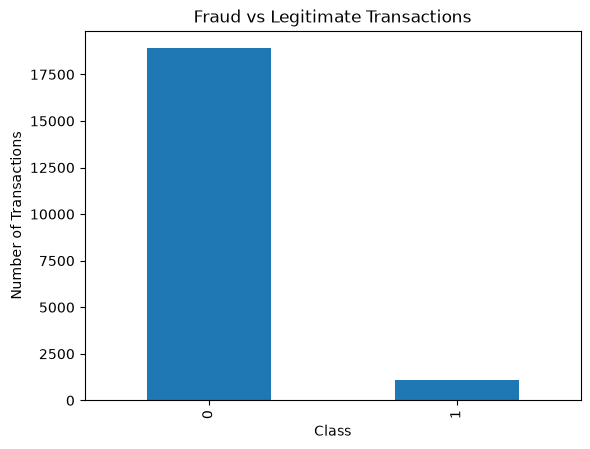

In [8]:
df["fraud"].value_counts().plot(
    kind="bar",
    title="Fraud vs Legitimate Transactions"
)
plt.xlabel("Class")
plt.ylabel("Number of Transactions")
plt.show()

## Step 5: Separate Features and Target

In [9]:
X = df.drop("fraud", axis=1)
y = df["fraud"]
print(X.shape)
print(y.shape)

(20000, 20)
(20000,)


In [10]:
X.columns

Index(['transaction_amount', 'account_age', 'transaction_frequency',
       'credit_score', 'customer_income', 'previous_defaults',
       'international_transaction', 'device_risk', 'ip_risk', 'merchant_risk',
       'location_risk', 'transaction_velocity', 'failed_attempts',
       'average_transaction', 'unusual_hour', 'new_device',
       'distance_from_home', 'payment_risk', 'account_activity',
       'behavior_deviation'],
      dtype='str')

In [11]:
y

0        0
1        0
2        0
3        0
4        0
        ..
19995    0
19996    0
19997    0
19998    0
19999    0
Name: fraud, Length: 20000, dtype: int64

## Step 6: Train-Test Split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Training fraud percentage:", y_train.mean() * 100 )
print("Testing fraud percentage:", y_test.mean() * 100)

Training: (16000, 20)
Testing: (4000, 20)
Training fraud percentage: 5.5125
Testing fraud percentage: 5.525


## Step 7: Train a Decision Tree Baseline

In [13]:
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))
print("Decision Tree Precision:", precision_score(y_test, dt_pred, zero_division=0))
print("Decision Tree Recall:", recall_score(y_test, dt_pred, zero_division=0))
print("Decision Tree F1:", f1_score(y_test, dt_pred, zero_division=0))

Decision Tree Accuracy: 0.94275
Decision Tree Precision: 0.483739837398374
Decision Tree Recall: 0.5384615384615384
Decision Tree F1: 0.5096359743040685


## Step 8: Train Random Forest

In [15]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    bootstrap=True,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

## Step 9: Evaluate Random Forest

In [16]:
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print("Random Forest Precision:", precision_score(y_test, rf_pred, zero_division=0))
print("Random Forest Recall:", recall_score(y_test, rf_pred, zero_division=0))
print("Random Forest F1:", f1_score(y_test, rf_pred, zero_division=0))
print("Classification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.966
Random Forest Precision: 0.9775280898876404
Random Forest Recall: 0.3936651583710407
Random Forest F1: 0.5612903225806452
Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3779
           1       0.98      0.39      0.56       221

    accuracy                           0.97      4000
   macro avg       0.97      0.70      0.77      4000
weighted avg       0.97      0.97      0.96      4000



## Step 10: Confusion Matrix

[[3777    2]
 [ 134   87]]


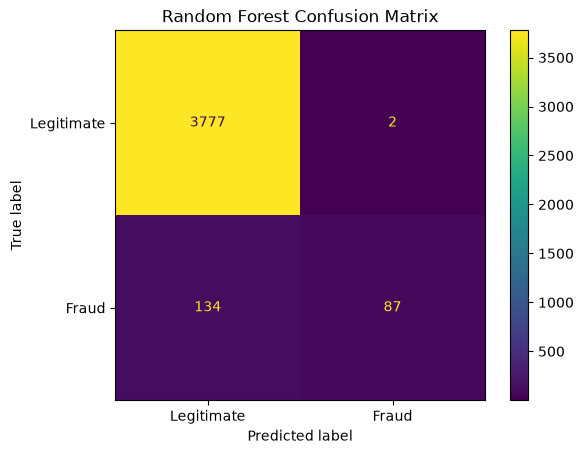

In [30]:
cm = confusion_matrix(y_test, rf_pred)
print(cm)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
).plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

## Step 11: ROC-AUC

In [31]:
rf_probability = rf_model.predict_proba(X_test)[:, 1]
roc_score = roc_auc_score(
    y_test,
    rf_probability
)
print("ROC-AUC:", roc_score)

ROC-AUC: 0.9553605960062694


## Step 12: Cross-Validation

In [17]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)
print("Cross Validation Scores:", cv_scores)
print("Mean CV Score:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Cross Validation Scores: [0.51666667 0.49361702 0.44736842 0.48101266 0.50209205]
Mean CV Score: 0.4881513634865894
Standard Deviation: 0.023458679345478906


## Step 13: Out-of-Bag Evaluation

In [ ]:
oob_model = RandomForestClassifier(
    n_estimators=200,
    bootstrap=True,
    oob_score=False,
    random_state=42,
    n_jobs=-1
)
oob_model.fit(X_train, y_train)
print("OOB Score:", oob_model.oob_score_)

OOB Score: 0.963625


## Step 14: GridSearchCV

In [ ]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        bootstrap=True,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)
print("Best Parameters:")
print(grid_search.best_params_)
print("Best CV Score:")
print(grid_search.best_score_)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


## Step 15: Evaluate the Best GridSearch Model

In [ ]:
best_rf = grid_search.best_estimator_
best_pred = best_rf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, best_pred))
print("Precision:", precision_score(y_test, best_pred, zero_division=0))
print("Recall:", recall_score(y_test, best_pred, zero_division=0))
print("F1:", f1_score(y_test, best_pred, zero_division=0))
print(classification_report(y_test, best_pred))

## Step 16: RandomizedSearchCV

In [ ]:
random_params = {
    "n_estimators": randint(100, 501),
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": randint(2, 16),
    "min_samples_leaf": randint(1, 10),
    "max_features": ["sqrt", "log2", None],
    "class_weight": [None, "balanced", "balanced_subsample"]
}
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        bootstrap=True,
        random_state=42,
        n_jobs=1
    ),
    param_distributions=random_params,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
random_search.fit(X_train, y_train)
print("Best Parameters:")
print(random_search.best_params_)
print("Best CV Score:")
print(random_search.best_score_)

## Step 17: Evaluate RandomizedSearchCV Model

In [ ]:
random_best_model = random_search.best_estimator_
random_best_pred = random_best_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, random_best_pred))
print("Precision:", precision_score(y_test, random_best_pred, zero_division=0))
print("Recall:", recall_score(y_test, random_best_pred, zero_division=0))
print("F1:", f1_score(y_test, random_best_pred, zero_division=0))

## Step 18: Feature Importance in Random Forest

Random Forest provides Mean Decrease in Impurity (MDI) feature importance.

*Limitations:* MDI is not causal, can favor high-cardinality features, and may divide importance across correlated features.

In [10]:
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
})
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)
print(importance_df)
importance_df.head(10).plot(
    x="Feature",
    y="Importance",
    kind="bar",
    figsize=(12, 5),
    legend=False
)
plt.title("Top 10 Important Features")
plt.xticks(rotation=45)
plt.show()

NameError: name 'best_rf' is not defined

## Step 19: Permutation Importance

Permutation importance measures performance drop when feature values are shuffled.

In [ ]:
from sklearn.inspection import permutation_importance
perm_result = permutation_importance(
    best_rf,
    X_test,
    y_test,
    n_repeats=10,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean
})
permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)
print(permutation_df)

## Step 20: Handling Missing Values Using a Pipeline

In [11]:
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ))
])
pipeline.fit(X_train, y_train)
pipeline_pred = pipeline.predict(X_test)
print(classification_report(y_test, pipeline_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3779
           1       0.98      0.39      0.56       221

    accuracy                           0.97      4000
   macro avg       0.97      0.70      0.77      4000
weighted avg       0.97      0.97      0.96      4000



## Step 21: Random Forest Regression

Predicting continuous target variables (e.g., house prices). The forest averages all individual tree predictions.

In [12]:
from sklearn.datasets import make_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV
)

X, y = make_regression(
    n_samples=10000,
    n_features=10,
    n_informative=8,
    noise=20,
    random_state=42
)
reg_columns = [
    "area",
    "bedrooms",
    "bathrooms",
    "property_age",
    "distance_city",
    "parking",
    "floor",
    "locality_score",
    "amenities_score",
    "connectivity_score"
]
reg_df = pd.DataFrame(X, columns=reg_columns)
reg_df["house_price"] = y
X = reg_df.drop("house_price", axis=1)
y = reg_df["house_price"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

rf_reg = RandomForestRegressor(
    n_estimators=200,
    criterion="squared_error",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)
rf_reg.fit(X_train, y_train)
reg_pred = rf_reg.predict(X_test)
print("MAE:", mean_absolute_error(y_test, reg_pred))
print("MSE:", mean_squared_error(y_test, reg_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, reg_pred)))
print("R2 Score:", r2_score(y_test, reg_pred))

MAE: 28.54901780504224
MSE: 1374.601729919926
RMSE: 37.075621773881636
R2 Score: 0.9385225930458991


### Regression Hyperparameter Tuning

In [ ]:
reg_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.5, 0.8, 1.0]
}
reg_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
reg_grid = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_grid=reg_param_grid,
    scoring="neg_mean_absolute_error",
    cv=reg_cv,
    n_jobs=-1,
    verbose=1
)
reg_grid.fit(X_train, y_train)
print("Best Parameters:")
print(reg_grid.best_params_)
print("Best CV MAE:")
print(-reg_grid.best_score_)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
